# Analysis of GO Textual Semantic Context

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## Load Data

In [2]:
go_df = pd.read_csv('./data/go/go-basic.csv')
go_df.shape

(40939, 5)

## Visualize GO Definition Word Counts

Here, we analyze the word counts of GO term definitions. The definitions are usually short with few distinctive words between them, thus lower dimensional embeddings might capture the variance in the data. Consider:

1. Reduce dimensionality with PCA
2. Reduce embedding dimension directly
3. Learn compressed embedding representations using autoencoders
4. Augment data by paraphrasing or expanding sentences.
5. Provide enriched context (e.g., categorical variables such as BP, MF and CC)
6. Use Max-pooling (instead of Mean-pooling) to emphasize the strongest signals
7. Use attention mechanism to focus on relevant features (already implemented in the model)
8. Regularize the embedding space (already implemented in the model)


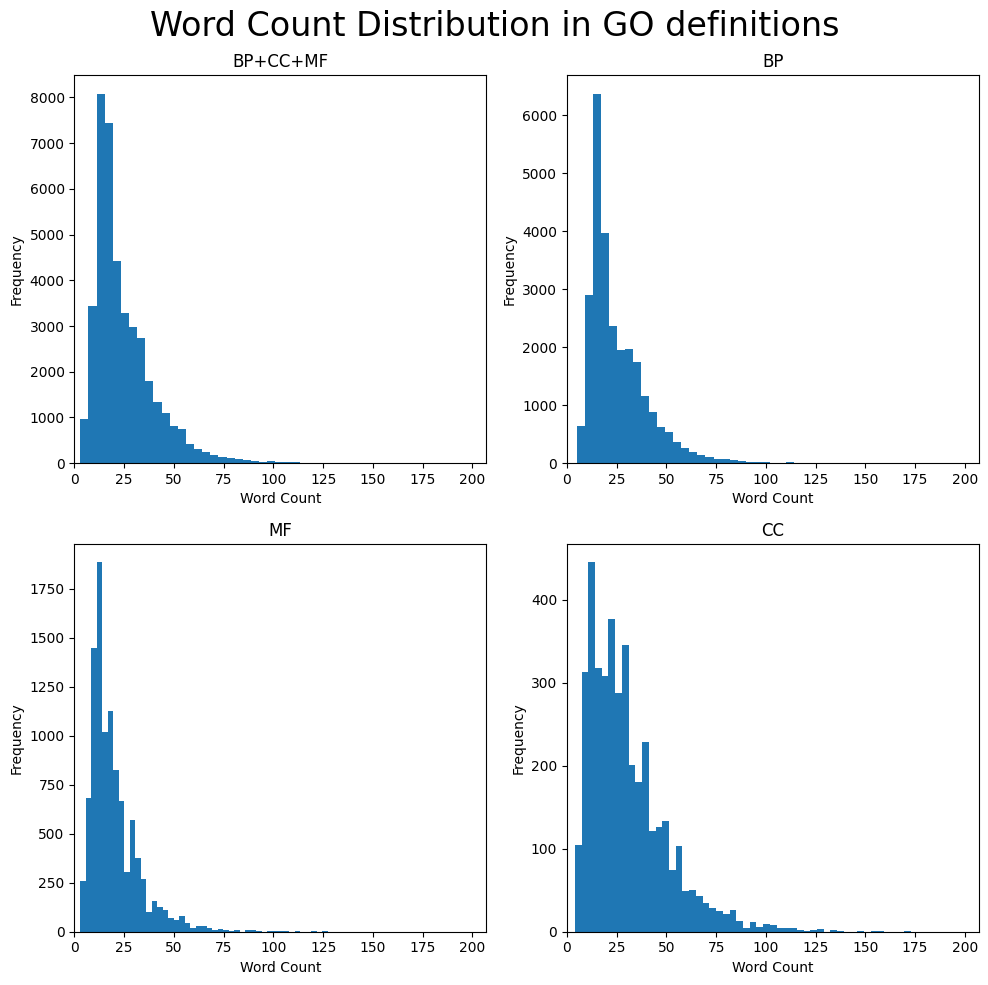

In [3]:
# Create subplots for all, BP, MF and CC namespaces
fig, ax = plt.subplots(2, 2, figsize=(10, 10))
ax = ax.flatten()

# Define namespaces, including one for the combined plot
namespaces = {
    "all": "BP+CC+MF",  # For the combined plot
    "biological_process": "BP",
    "molecular_function": "MF",
    "cellular_component": "CC",
}

# Single loop for plotting
for i, (namespace, code) in enumerate(namespaces.items()):
    if namespace == "all":
        # Plot for all namespaces combined
        go_df["def_word_count"].plot(
            kind="hist",
            xlim=(0, max(go_df["def_word_count"].values)),
            title=code,
            xlabel="Word Count",
            ylabel="Frequency",
            ax=ax[i],
            bins=50,
        )
    else:
        # Plot for individual namespaces
        go_df[go_df["namespace"] == namespace]["def_word_count"].plot(
            kind="hist",
            xlim=(0, max(go_df["def_word_count"].values)),
            title=code,
            xlabel="Word Count",
            ylabel="Frequency",
            ax=ax[i],
            bins=50,
        )

fig.suptitle("Word Count Distribution in GO definitions", fontsize=24)
plt.tight_layout()
plt.show()